# Thesis project: Entanglement of Local Quench
---
As a benchmark, we use the MFI Hamiltonian
\begin{align}
	H = J \sum_{i=1}^{L-1} S_{i}^z S_{i+1}^z + h \sum_{i=1}^{L} S_{i}^{x} + g \sum_{i=1}^L S_{i}^{z}
\end{align}

For the sake of simplicity, we replace spin operators by Pauli matrices.

The reason for the choice of model (MFI Hamiltonian) is because for generic nonzero transverse and longitudinal fields, the mixed-field Ising model is nonintegrable and has no useful on-site spin conservation law. The longitudinal field breaks the usual global Ising spin-flip symmetry. Energy remains conserved, and a spatial reflection symmetry may remain for uniform couplings and open boundaries.

Moreover, there is no known generic exact solution to this Hamiltonian. The solution is expected to exhibit chaotic dynamics in suitable parameter regimes.

# Objective of the notebook
---

The main objective of this notebook is to answer the following question:

> "After applying a local pertubation to a thermal spin chain, is it computationally better to evolve the complete thermal state or only the local pertubation operator?"

We implement and compare two TEBD pipelines: Direct thermal-state evolution and Heisenberg operator evolution.

Both pipelines should produce the response of an observable $O$ after a local kick of strength $\lambda$, which is $\braket{O(t)}_{\lambda}$. In this notebook, the pertubation is $\sigma_z$.

At the end, they should be compared in terms of accuracy, bond dimension, truncation error and maximum reachable time.


First, we implement some libraries:

In [2]:
# Libraries
# ---------

import numpy as np
from matplotlib import pyplot as plt
import tenpy as tp
from tqdm import tqdm # Executed together with the loop to see the process
npc = tp.linalg.np_conserved
npc_arr = npc.Array.from_ndarray_trivial
tr = tp.linalg.truncation

For computing local observable:

In [3]:
# For computing local observable
# ------------------------------

def local_observable_mps(O, mps, i):
    G, s = mps
    G_scaled = G[i].scale_axis(s[i], axis='vR').scale_axis(s[i-1], axis='vL')
    upper = npc.tensordot(G_scaled, O, axes = ['p', 'p*'])
    return npc.tensordot(upper, G_scaled.conj(), axes = [['p','vL', 'vR'], ['p*','vL*', 'vR*']])

For computing two point correlation:

In [4]:
# For computing two point correlation
# -----------------------------------

def two_point_correlation_mps(Oi, Oj, mps, i, j):
	G, s = mps
	O = [None] * L
	O[i] = Oi
	O[j] = Oj
	
	ker = npc_arr([[1.]],labels=['vR','vR*']) # start contraction from a trivial 1x1 tensor

	# Compute overlap with `zipper` algorithm
	# ---------------------------------------
	for _ in range(L):
		ker = npc.tensordot(ker, # incorporate upper tensor
			G[i].scale_axis(s1[i], axis='vR'),
			axes = ['vR', 'vL'])
		ker = npc.tensordot(ker, # incorporate lower tensor
			G[i].scale_axis(s2[i], axis='vR').conj(),
			axes = ['vR*', 'vL*'])
		if _ == i or _ == j:
			ker = npc.tensordot(ker,
			O[_], axes = ['p', 'p*']
			)
		ker = npc.trace(ker,leg1='p',leg2='p*') # contract physical legs

	return npc.trace(ker)

This is the implementation of the TEBD storing the outcome MPS along with the local measurement history (when needed)

In [ ]:

def copy_mps(mps):
    """Deep-copy the custom (G, s) MPS representation."""
    G, s = mps
    return [tensor.copy() for tensor in G], [values.copy() for values in s]


def bond_entropy_from_singular_values(values):
    """
    Von Neumann entropy associated with one MPS bond.

    The values are Schmidt coefficients.  We normalize their squared
    magnitudes because vectorized operators need not have unit norm.
    """
    weights = np.abs(np.asarray(values, dtype=complex))**2
    norm = np.sum(weights)

    if norm <= 0.0:
        return 0.0

    probabilities = weights / norm
    probabilities = probabilities[probabilities > 0.0] # to compute von Neumann entropy, log0 is not defined

    return float(-np.sum(probabilities * np.log(probabilities)))


def mps_complexity(mps, half_bond=None):
    """
    Return maximum bond dimension and entropy across a central bond.
    """
    G, s = mps
    L_local = len(G)

    if half_bond is None:
        # For odd L this chooses one of the two central bipartitions.
        half_bond = (L_local - 1) // 2

    return {
        "max_bond_dimension": max(len(values) for values in s),
        "half_chain_entropy": bond_entropy_from_singular_values(
            s[half_bond]
        ),
    }


def tebd_run(
    initial_mps,
    list_of_bond_hams,
    dt,
    n_steps,
    chi_max,
    eps,
    O=None,
    return_diagnostics=False,
    store_mps_every=None,
):
    """
    Original first-order even/odd TEBD, extended minimally.

    New optional outputs
    --------------------
    diagnostics:
        Bond dimension, central-bond entropy and discarded weight after
        every complete even+odd TEBD step.

    snapshots:
        Sparse copies of the evolved MPS.  These are needed to evaluate
        the linear-response correlators at several times without storing
        every time step.

    Existing notebook calls remain valid because, by default, the
    function still returns only

        final_mps, measurement_history.
    """
    G, s = copy_mps(initial_mps)
    measurement = []

    diagnostics = {
        "times": [0.0],
        "max_bond_dimension": [],
        "half_chain_entropy": [],
        "step_discarded_weight": [0.0],
        "cumulative_discarded_weight": [0.0],
        "hit_chi_max": [],
    }

    initial_complexity = mps_complexity((G, s))
    diagnostics["max_bond_dimension"].append(
        initial_complexity["max_bond_dimension"]
    )
    diagnostics["half_chain_entropy"].append(
        initial_complexity["half_chain_entropy"]
    )
    diagnostics["hit_chi_max"].append(
        initial_complexity["max_bond_dimension"] >= chi_max
    )

    snapshots = {
        "steps": [],
        "times": [],
        "mps": [],
    }

    if store_mps_every is not None:
        if store_mps_every < 1:
            raise ValueError("store_mps_every must be a positive integer.")

        snapshots["steps"].append(0)
        snapshots["times"].append(0.0)
        snapshots["mps"].append(copy_mps((G, s)))

    # Turn Hamiltonian/Liouvillian bonds into exp(-i h_j dt).
    list_of_bonds = [
        npc.expm(
            H.combine_legs(["p1", "p2"])
             .combine_legs(["p1*", "p2*"])
            * (-1.0j) * dt
        ).split_legs()
        for H in list_of_bond_hams
    ]

    if O is not None:
        measurement.append([
            local_observable_mps(O, (G, s), site)
            for site in range(len(G))
        ])

    cumulative_discarded_weight = 0.0
    discarded_in_current_step = 0.0

    # One physical time step consists of one even and one odd layer.
    for layer in tqdm(range(2 * n_steps)):
        for bond in range(layer % 2, len(list_of_bonds), 2):
            G[bond] = (
                G[bond]
                .scale_axis(s[bond - 1], axis="vL")
                .scale_axis(s[bond], axis="vR")
                .replace_label("p", "p1")
            )
            G[bond + 1] = (
                G[bond + 1]
                .scale_axis(s[bond + 1], axis="vR")
                .replace_label("p", "p2")
            )

            two_site_tensor = npc.tensordot(
                npc.tensordot(
                    G[bond],
                    G[bond + 1],
                    axes=["vR", "vL"],
                ),
                list_of_bonds[bond],
                axes=[["p1", "p2"], ["p1*", "p2*"]],
            ).combine_legs(
                ["vL", "p1"]
            ).combine_legs(
                ["vR", "p2"]
            )

            G[bond], singular_values, G[bond + 1] = npc.svd(
                two_site_tensor,
                inner_labels=["vR", "vL"],
            )

            # Decide which singular values are retained.
            singular_values = np.asarray(singular_values)
            mask = np.zeros(len(singular_values), dtype=bool)
            mask[:min(len(singular_values), chi_max)] = True
            mask[np.abs(singular_values) < eps] = False

            if not np.any(mask):
                # Keep the largest value rather than producing an empty bond.
                mask[np.argmax(np.abs(singular_values))] = True

            squared = np.abs(singular_values)**2
            total_weight = np.sum(squared)
            discarded_weight = (
                np.sum(squared[~mask]) / total_weight
                if total_weight > 0.0
                else 0.0
            )
            discarded_in_current_step += float(discarded_weight)

            # Remove the neighbouring Schmidt values which were absorbed
            # before the SVD.
            inv_left = np.where(
                np.abs(s[bond - 1]) > eps,
                1.0 / s[bond - 1],
                0.0,
            )
            inv_right = np.where(
                np.abs(s[bond + 1]) > eps,
                1.0 / s[bond + 1],
                0.0,
            )

            G[bond] = (
                G[bond]
                .split_legs()
                .scale_axis(inv_left, axis="vL")
                .replace_label("p1", "p")
            )
            G[bond + 1] = (
                G[bond + 1]
                .split_legs()
                .scale_axis(inv_right, axis="vR")
                .replace_label("p2", "p")
            )

            G[bond].iproject(mask, axes="vR")
            G[bond + 1].iproject(mask, axes="vL")

            s[bond] = singular_values[mask]
            s[bond] = s[bond] / np.linalg.norm(s[bond]) #normalize the vector

        # Record only after a complete even+odd step.
        if layer % 2 == 1:
            physical_step = (layer + 1) // 2
            physical_time = physical_step * dt

            if O is not None:
                measurement.append([
                    local_observable_mps(O, (G, s), site)
                    for site in range(len(G))
                ])

            cumulative_discarded_weight += discarded_in_current_step
            complexity = mps_complexity((G, s))

            diagnostics["times"].append(physical_time)
            diagnostics["max_bond_dimension"].append(
                complexity["max_bond_dimension"]
            )
            diagnostics["half_chain_entropy"].append(
                complexity["half_chain_entropy"]
            )
            diagnostics["step_discarded_weight"].append(
                discarded_in_current_step
            )
            diagnostics["cumulative_discarded_weight"].append(
                cumulative_discarded_weight
            )
            diagnostics["hit_chi_max"].append(
                complexity["max_bond_dimension"] >= chi_max
            )

            discarded_in_current_step = 0.0

            should_store = (
                store_mps_every is not None
                and (
                    physical_step % store_mps_every == 0
                    or physical_step == n_steps
                )
            )

            if should_store:
                snapshots["steps"].append(physical_step)
                snapshots["times"].append(physical_time)
                snapshots["mps"].append(copy_mps((G, s)))

    final_mps = (G, s)

    if return_diagnostics or store_mps_every is not None:
        return final_mps, measurement, diagnostics, snapshots

    return final_mps, measurement


We modify it into a thermal TEBD:

In [ ]:
def thermal_tebd_run(initial_mps, list_of_bond_hams, dt, n_steps, chi_max, eps, O = None): 
    G = [i.copy() for i in initial_mps[0]]
    s = [i.copy() for i in initial_mps[1]]
    measurement = []
    # Turn hamiltonian into e^-Hdt
    list_of_bonds = [npc.expm(H.combine_legs(['p1', 'p2']).combine_legs(['p1*', 'p2*'])*(-1.0)*dt).split_legs() for H in list_of_bond_hams] # Imaginary-thermal-time gates exp(-Hdt)
    if O is not None:
        measurement.append([local_observable_mps(O, (G,s), k) for k in range(len(G))]) 
    for i in tqdm(range(2*n_steps)): #CHANGED
        for j in range(i%2,len(list_of_bonds),2):
            G[j] = G[j].scale_axis(s[j-1], axis = 'vL').scale_axis(s[j], axis = 'vR').replace_label('p', 'p1') 
            G[j+1] = G[j+1].scale_axis(s[j+1], axis = 'vR').replace_label('p', 'p2') 
            A = npc.tensordot(
					npc.tensordot(G[j], G[j+1], axes=['vR','vL']),
					list_of_bonds[j], axes = [['p1','p2'],['p1*','p2*']]
				).combine_legs(['vL','p1']).combine_legs(['vR', 'p2']) 
            G[j], s[j], G[j+1] =  npc.svd(A, inner_labels = ['vR', 'vL'])
            # To prevent blowing up when deincoporating too small singular values
            inv_sq_L = np.where(s[j-1] > eps, 1. / s[j-1], 0.0)
            inv_sq_R = np.where(s[j+1] > eps, 1. / s[j+1], 0.0)

            G[j] = G[j].split_legs().scale_axis(inv_sq_L, axis='vL').replace_label('p1','p') # de-incorporate s[j-1] in the tensor
            G[j+1] = G[j+1].split_legs().scale_axis(inv_sq_R, axis = 'vR').replace_label('p2', 'p')



            # Perform truncation and renormalization
            # --------------------------------------


            mask = np.zeros(len(s[j]), dtype = bool)
            mask[0:min(len(s[j]),chi_max)] = True
            mask[s[j] < eps] = False
            
            G[j].iproject(mask, axes = 'vR')
            G[j+1].iproject(mask, axes = 'vL')
             
            s[j] = s[j][mask]
            s[j] = s[j] / np.linalg.norm(s[j])
        

        # Store measurement after every 2 steps (even and odd)
        if i%2 == 1 and O is not None:
            measurement.append([local_observable_mps(O, (G,s), k) for k in range(len(G))]) 
    return (G, s), measurement #CHANGED

This converts a list of vector into an MPS:

In [7]:
# Convert a list of vectors into an MPS (vectorize an operator)
# -------------------------------------------------------------

def build_product_mps(list_vectors):
    G = []
    norm = 1
    s = [np.array([1.]) for _ in list_vectors] #CHANGED
    for v in list_vectors:
        norm *= np.linalg.norm(v)
        G.append(npc_arr(v/np.linalg.norm(v), labels = 'p').add_trivial_leg(label='vL').add_trivial_leg(label='vR'))
    return G, s, norm

Having all the important tools together, our workflow is now as following:
> **First pipeline**: Direct evolution of a kicked thermal purification
1. Construct the purified MFI bond Hamiltonians;
2. Prepare a finite-temperature purified state;
3. Implement the local kick and apply it on the thermalized MPS;
4. Evolve the kicked and unquenched purification in real time to plot the response;
> **Second pipeline**: Linear response from an evolved local operator
5. Represent a local operator as an MPO or vectorized MPS;
6. Construct the Liouvillian bonds to evolve the local operator;
7. Compute correlation functions for every site;
8. Compute the response and compare it with the direct pipeline.

---
# **Direct evolution of a kicked thermal purification**
---

## Task 1
Construct the purified MFI bond Hamiltonians:

In [8]:
# Define the list of purified Hamiltonian bonds for TFI Hamiltonian
# -----------------------------------------------------------------
sx = np.array([[0, 1], [1, 0]], dtype=complex)
sz = np.array([[1, 0], [0, -1]], dtype=complex)
id2 = np.eye(2, dtype = complex)

# For later measurements, it is also good to defined the purified operators
# -------------------------------------------------------------------------
sx_purified = npc_arr(np.kron(sx, id2), labels = ['p', 'p*'])
sz_purified = npc_arr(np.kron(sz, id2), labels = ['p', 'p*'])

def list_of_ham_bonds(J,h,g,L):
    list_of_bonds = []
    for _ in range(L-1):
        if _ == 0:
            list_of_bonds.append(npc_arr(np.einsum("abcd,ef,gh -> aebgcfdh",
                                                   (J*np.kron(sz,sz)+g*np.kron(sz,id2)+h*np.kron(sx,id2)+g*np.kron(id2,sz)/2+h*np.kron(id2,sx)/2).reshape(2,2,2,2),
                                                   id2, id2).reshape(4,4,4,4), 
                                                   labels = ["p1", "p2", "p1*", "p2*"]))
        elif _ == L-2:
            list_of_bonds.append(npc_arr(np.einsum("abcd,ef,gh -> aebgcfdh",
                                                   (J*np.kron(sz,sz)+(g*np.kron(sz,id2)+h*np.kron(sx,id2))/2+g*np.kron(id2,sz)+h*np.kron(id2,sx)).reshape(2,2,2,2),
                                                    id2, id2).reshape(4,4,4,4),
                                                    labels = ["p1", "p2", "p1*", "p2*"]))
        else:
            list_of_bonds.append(npc_arr(np.einsum("abcd,ef,gh -> aebgcfdh",
                                                   (J*np.kron(sz,sz)+(g*np.kron(sz,id2)+h*np.kron(sx,id2)+g*np.kron(id2,sz)+h*np.kron(id2,sx))/2).reshape(2,2,2,2),
                                                    id2, id2).reshape(4,4,4,4),
                                                    labels = ["p1", "p2", "p1*", "p2*"]))
    return list_of_bonds

## Task 2
Prepare a finite-temperature purified state.
> **Note!**: If the measurement is stored, the operator must also be purified. Also, $\beta$ should be chosen small enough, so that the MPS bond dimension stays moderate. For the real-time evolution after the thermal evolution and local quench, this is of central importance.

In [9]:
def prepare_finite_temperature_purification(J,h,g,L,beta, dt, chi_max, eps, O):
    G_zero, s_zero, norm_zero = build_product_mps([np.array([1,0,0,1], dtype = complex) for _ in range(L)])
    mps_zero = (G_zero, s_zero)
    psi_beta, thermal_measurements = thermal_tebd_run(mps_zero, list_of_ham_bonds(J,h,g,L), dt, int(round(beta/(2*dt))), chi_max, eps, O)
    return psi_beta, thermal_measurements

We test if the implementation of the thermal pipeline is correct:

100%|██████████| 200/200 [00:38<00:00,  5.14it/s]


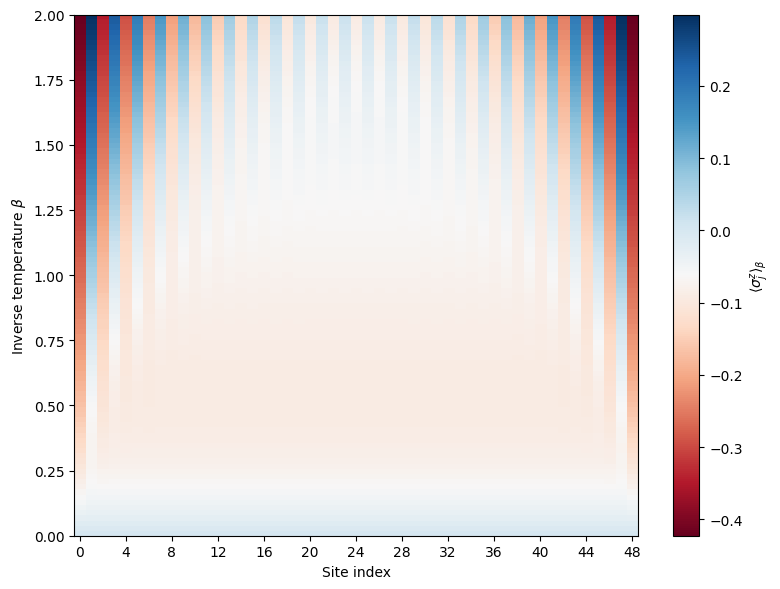

In [10]:
def test_thermal(J = 1.0, h = 0.5, g = 0.5, L = 49, beta = 2.0, dt = 0.01, chi_max = 30, eps = 1e-12):

    final_mps, sz_history = prepare_finite_temperature_purification(
        J=J,
        h=h,
        g=g,
        L=L,
        beta=beta,
        dt=dt,
        chi_max=chi_max,
        eps=eps,
        O=sz_purified
    )

    plt.figure(figsize=(8, 6))

    plt.imshow(
        np.real(sz_history),
        aspect='auto',
        origin='lower',
        cmap='RdBu',
        interpolation='none',
        extent=[-0.5, L - 0.5, 0, beta]
    )

    plt.colorbar(label=r'$\langle \sigma^z_j\rangle_\beta$')
    plt.xlabel('Site index')
    plt.ylabel(r'Inverse temperature $\beta$')
    # plt.title(f'Thermal preparation of $S^z$ density, $L={L}$')
    plt.xticks(np.arange(0, L, step=max(1, L // 10)))
    plt.tight_layout()
    plt.show()


test_thermal()

We would pass the test, if with increasing $\beta$, alternating magnetization appears. This is expected from the AFM Neel pattern. $J > 0 $ means neighbouring spins favour opposite directions. For small $\beta$, high entropy leads to disappearance of netto magnetization.

## Task 3
Implement a local kick and apply it on the thermalized MPS
> **Note!**: For now, we use $U_{\lambda} = e^{-i \lambda \sigma_{L//2}^z}$ as a local operator. Of course, it could be in a different form.

In [11]:
def local_kick_operator(lambda_value, purified_operator):
    # lambda is a reserved Python keyword
    return npc.expm(-1.0j * lambda_value * purified_operator)

def apply_local_kick(mps, operator, site):
    G, s = mps
    # We make independent copy so that the initial MPS is preserved
    G_kicked = [i.copy() for i in G]
    s_kicked = [i.copy() for i in s]

    G_kicked[site] = npc.tensordot(G_kicked[site], operator, axes = ['p', 'p*'])
    return G_kicked, s_kicked

In [12]:
J = 1.0
h = 0.5
g = 0.5
L = 49
beta = 1.0
dt = 0.01
chi_max = 2**7
eps = 1e-12

psi_beta, thermal_measurements = prepare_finite_temperature_purification(J, h, g, L, beta, dt, chi_max, eps, sz_purified)

100%|██████████| 100/100 [00:06<00:00, 16.15it/s]


In [13]:
lambda_value = 0.01

psi_kicked = apply_local_kick(
    mps = psi_beta,
    operator = local_kick_operator(lambda_value, sz_purified),
    site = L//2
)

Test if the kick matrix is unitary

In [14]:
def test_unitary_kick():
    U_numpy = local_kick_operator(lambda_value, sz_purified).to_ndarray()
    display(np.max(np.abs(U_numpy.conj().T @ U_numpy- np.eye(4))))

test_unitary_kick()

np.float64(0.0)

## Task 4

Evolve the kicked and unquenched purification in real time to plot the response

In [15]:

real_dt = 0.05
real_n_steps = 400

In [ ]:
psi_kicked_t, sz_time_history, kicked_diagnostics, _ = tebd_run(
    initial_mps=psi_kicked,
    list_of_bond_hams=list_of_ham_bonds(J, h, g, L),
    dt=real_dt,
    n_steps=real_n_steps,
    chi_max=chi_max,
    eps=eps,
    O=sz_purified,
    return_diagnostics=True,
)


100%|██████████| 800/800 [2:30:00<00:00, 11.25s/it]  


In [ ]:
psi_unpertubed_t, sz_unpertubed_time_history, unperturbed_diagnostics, _ = tebd_run(
    initial_mps=psi_beta,
    list_of_bond_hams=list_of_ham_bonds(J, h, g, L),
    dt=real_dt,
    n_steps=real_n_steps,
    chi_max=chi_max,
    eps=eps,
    O=sz_purified,
    return_diagnostics=True,
)


100%|██████████| 800/800 [2:26:55<00:00, 11.02s/it]  


In [ ]:
direct_response_time = (
    np.real(np.asarray(sz_time_history))
    - np.real(np.asarray(sz_unpertubed_time_history))
) / lambda_value

direct_times = np.arange(real_n_steps + 1) * real_dt

Plot of $\frac{\braket{S^z_{j}}_{\lambda}(t) - \braket{S^z_{j}}_{0}(t)}{\lambda}$

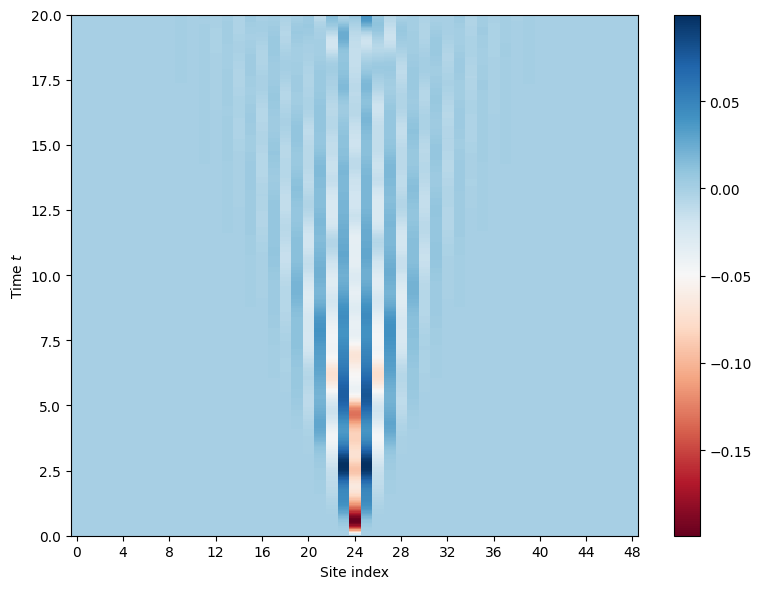

In [ ]:

plt.figure(figsize=(8, 6))

plt.imshow(
    direct_response_time,
    aspect="auto",
    origin="lower",
    cmap="RdBu",
    interpolation="none",
    extent=[-0.5, L - 0.5, 0, real_dt * real_n_steps],
)

plt.colorbar()
#plt.colorbar(label=r"$[\langle \sigma^z_j\rangle_\lambda"
# "-\langle \sigma^z_j\rangle_0]/\lambda$"
#)
plt.xlabel("Site index")
plt.ylabel(r"Time $t$")
# plt.title(
#    rf"Direct finite-kick response, "
#    rf"$\lambda={lambda_value}$, $L={L}$"
#)
plt.xticks(np.arange(0, L, step=max(1, L // 10)))
plt.tight_layout()
plt.show()


---
# **Linear response from an evolved local operator**
---

## Task 5
Represent and evolve a local operator as an MPO or vectorized MPS
> **Note!**: The TEBD we implemented evolves an MPS, it is of course the natural choice to represent the local quench as an MPS. We again use $U_{\lambda} = e^{-i \lambda \sigma_{L//2}^z}$ as the local operator.

In [ ]:
# Define the vectorized Pauli operators (NumPy uses the row-major vectorization)
# ------------------------------------------------------------------------------
id2_vector = id2.reshape(-1).astype(complex)
sz_vector = sz.reshape(-1).astype(complex)
sx_vector = sx.reshape(-1).astype(complex)

In [ ]:
def build_local_operator_mps(L, site, vectorized_local_operator):
    list_vectors = [id2_vector.copy() for _ in range(L)]
    list_vectors[site] = vectorized_local_operator
    G, s, operator_norm = build_product_mps(list_vectors)
    return (G,s), operator_norm

Define the local quench operator as a vectorized MPS:

In [ ]:
V_mps, V_norm = build_local_operator_mps(L, L//2, sz_vector)

## Task 6
Construct the Liouvillian bonds to evolve the local operator

In [ ]:
def list_of_liouvillian_bonds(J, h, g, L):
    """
    Directly construct the bond Liouvillians for

        H = J sum_j sz_j sz_{j+1}
            + h sum_j sx_j
            + g sum_j sz_j

    using row-major vectorization:

        vec(A X B) = (A kron B.T) vec(X).

    Each vectorized site has local dimension 4.
    """

    id4 = np.eye(4, dtype=complex)

    # Left multiplication: A X -> (A kron I) |X>
    sx_left = np.kron(sx, id2)
    sz_left = np.kron(sz, id2)

    # Right multiplication: X A -> (I kron A^T) |X>
    sx_right = np.kron(id2, sx.T)
    sz_right = np.kron(id2, sz.T)

    # One-site commutator generated by the fields
    field_liouvillian = (h * (sx_left - sx_right) + g * (sz_left - sz_right))

    list_of_bonds = []

    for j in range(L - 1):

        # Boundary-field bookkeeping
        left_weight = 1.0 if j == 0 else 0.5
        right_weight = 1.0 if j == L - 2 else 0.5

        # Interaction commutator:
        #
        # (sz_j sz_j+1) X - X (sz_j sz_j+1)
        interaction_liouvillian = J * (np.kron(sz_left, sz_left) - np.kron(sz_right, sz_right))

        # Field acting on the left site of this bond
        left_field_liouvillian = (left_weight * np.kron(field_liouvillian, id4))

        # Field acting on the right site of this bond
        right_field_liouvillian = (right_weight* np.kron(id4, field_liouvillian))

        L_bond = (interaction_liouvillian + left_field_liouvillian + right_field_liouvillian)

        list_of_bonds.append(npc_arr(L_bond.reshape(4, 4, 4, 4), labels=["p1", "p2", "p1*", "p2*"]))

    return list_of_bonds

Now we evolve the operator to $V(-t)$ using TEBD applied on the Liouvillain bonds

In [ ]:

operator_dt = real_dt
operator_n_steps = real_n_steps

# Correlator contraction is substantially more expensive than one TEBD
# step.  Store the operator every 1 physical steps, corresponding here
# to a sampling interval of 0.05.
operator_sample_every = 1

V_minus_t_mps, _, operator_diagnostics, operator_snapshots = tebd_run(
    initial_mps=V_mps,
    list_of_bond_hams=list_of_liouvillian_bonds(J, h, g, L),
    dt=operator_dt,
    n_steps=operator_n_steps,
    chi_max=chi_max,
    eps=eps,
    O=None,
    return_diagnostics=True,
    store_mps_every=operator_sample_every,
)


100%|██████████| 800/800 [2:07:19<00:00,  9.55s/it]  


As a side note: The bond dimensions grow as the operator spreads out:

In [ ]:
display(f"Initial bond dimensions: {[len(x) for x in V_mps[1]]}")
display(f"Final bond dimensions: {[len(x) for x in V_minus_t_mps[1]]}")

'Initial bond dimensions: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]'

'Final bond dimensions: [4, 16, 64, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 64, 16, 4, 1]'

## Task 7
Compute correlation functions for every site

In [ ]:
def ordinary_mps_site_tensor(mps, site):
    """
    Construct A_j = Gamma_j s_j as a NumPy array.

    Returned shape:
        (left_bond, physical, right_bond)
    """
    G, s = mps

    return (
        G[site]
        .scale_axis(s[site], axis="vR")
        .transpose(["vL", "p", "vR"])
        .to_ndarray()
    )

In [ ]:
def thermal_operator_correlator_profiles(thermal_mps, operator_mps, operator_norm, O_phys):
    """
    Compute, for every site j,

        C_VO[j] = <V(-t) O_j>_beta
        C_OV[j] = <O_j V(-t)>_beta

    using a fixed thermal purification and a vectorized operator MPS.

    Parameters
    ----------
    thermal_mps:
        Purified thermal state (G_beta, s_beta).
        Local fused basis: (physical, auxiliary).

    operator_mps:
        Vectorized operator state (G_op, s_op).
        Local fused basis: (output, input).

    operator_norm:
        Hilbert-Schmidt normalization removed by
        build_product_mps. For the local Pauli operator
        constructed previously, use V_norm.

    O_phys:
        Physical 2x2 observable, for example `sz`.

    Returns
    -------
    C_VO, C_OV:
        Complex arrays of shape (L,).
    """

    G_beta, _ = thermal_mps
    G_op, _ = operator_mps

    L = len(G_beta)

    if len(G_op) != L:
        raise ValueError("Thermal and operator MPS lengths do not match.")

    O_phys = np.asarray(O_phys, dtype=complex)

    if O_phys.shape != (2, 2):
        raise ValueError("O_phys must be a physical 2x2 matrix.")

    thermal_tensors = []
    operator_tensors = []

    for site in tqdm(range(L)):
        # Thermal tensor:
        # (left, fused physical-auxiliary, right)
        A = ordinary_mps_site_tensor(thermal_mps, site)

        if A.shape[1] != 4:
            raise ValueError(f"Thermal local dimension at site {site} is not 4.")

        # Split fused index into:
        # (left, physical, auxiliary, right)
        A = A.reshape(A.shape[0], 2, 2, A.shape[2])

        # Vectorized operator tensor:
        # (left, fused output-input, right)
        W = ordinary_mps_site_tensor(operator_mps, site)

        if W.shape[1] != 4:
            raise ValueError(f"Operator local dimension at site {site} is not 4.")

        # Split fused index into:
        # (left, output, input, right)
        W = W.reshape(W.shape[0], 2, 2, W.shape[2]) ################################################################

        thermal_tensors.append(A)
        operator_tensors.append(W)

    # ---------------------------------------------------------
    # Left environments
    #
    # left_env[j] contains the contraction of sites 0,...,j-1.
    #
    # Its indices are:
    # (thermal-bra bond, operator bond, thermal-ket bond)
    # ---------------------------------------------------------

    left_env = [None] * (L + 1)
    left_env[0] = np.ones((1, 1, 1), dtype=complex)

    for site in tqdm(range(L)):
        A = thermal_tensors[site]
        W = operator_tensors[site]

        # Contract tensors pairwise

        mkpax = np.einsum("lmk,lpax->mkpax", left_env[site], A.conj(), optimize = True)
        kaxqn = np.einsum("mkpax,mpqn->kaxqn", mkpax, W, optimize = True)
        left_env[site+1] = np.einsum("kaxqn,kqay->xny", kaxqn, A, optimize = True)

    del mkpax, kaxqn

        # left_env[site + 1] = np.einsum("lmk,lpax,mpqn,kqay->xny", left_env[site], A.conj(), W, A, optimize=True)

    # ---------------------------------------------------------
    # Right environments
    #
    # right_env[j] contains the contraction of sites j,...,L-1.
    # ---------------------------------------------------------

    right_env = [None] * (L + 1)
    right_env[L] = np.ones((1, 1, 1), dtype=complex)

    for site in tqdm(range(L - 1, -1, -1)):
        A = thermal_tensors[site]
        W = operator_tensors[site]

        # Contract tensors pairwise

        xnkqa = np.einsum("xny,kqay->xnkqa", right_env[site+1], A, optimize = True)
        xkamp = np.einsum("xnkqa,mpqn->xkamp", xnkqa, W, optimize = True)
        right_env[site] = np.einsum("xkamp,lpax->kml", xkamp, A.conj(), optimize = True).transpose(2,1,0) #kml to lmk
    
    del xnkqa, xkamp

        # right_env[site] = np.einsum("lpax,mpqn,kqay,xny->lmk", A.conj(), W, A, right_env[site + 1], optimize=True)

    C_VO = np.zeros(L, dtype=complex)
    C_OV = np.zeros(L, dtype=complex)

    for site in tqdm(range(L)):
        A = thermal_tensors[site]
        W = operator_tensors[site]

        # V(-t) O_j:
        #
        # (W O)_{p,q} = sum_r W_{p,r} O_{r,q}
        W_VO = np.einsum("lpsr,sq->lpqr", W, O_phys, optimize=True)

        # O_j V(-t):
        #
        # (O W)_{p,q} = sum_r O_{p,r} W_{r,q}
        W_OV = np.einsum("ps,lsqr->lpqr", O_phys, W, optimize=True)

        # Contract tensors pairwise

        mkpax = np.einsum("lmk,lpax->mkpax", left_env[site], A.conj(), optimize = True)
        kqaxn = np.einsum("kqay,xny->kqaxn", A, right_env[site+1], optimize = True)
        mpqn = np.einsum("mkpax,kqaxn->mpqn", mkpax, kqaxn, optimize = True)

        C_VO[site] = np.einsum("mpqn,mpqn->", mpqn, W_VO, optimize = True)
        C_OV[site] = np.einsum("mpqn,mpqn->", mpqn, W_OV, optimize = True)

    del mkpax, kqaxn, mpqn

        # C_VO[site] = np.einsum("lmk,lpax,mpqn,kqay,xny->", left_env[site], A.conj(), W_VO, A, right_env[site + 1], optimize=True)

        # C_OV[site] = np.einsum("lmk,lpax,mpqn,kqay,xny->", left_env[site], A.conj(), W_OV, A, right_env[site + 1], optimize=True)

    # The operator MPS was normalized by build_product_mps.
    # Restore the physical Hilbert-Schmidt normalization.
    C_VO *= operator_norm
    C_OV *= operator_norm

    return C_VO, C_OV

Now we use this function on `V_minus_t_msp`

In [ ]:

# Final-time correlators, as in the original notebook.
C_VO_final, C_OV_final = thermal_operator_correlator_profiles(
    thermal_mps=psi_beta,
    operator_mps=V_minus_t_mps,
    operator_norm=V_norm,
    O_phys=sz,
)

# Time-dependent correlators at the sparse operator snapshots.
C_VO_time = []
C_OV_time = []

for snapshot_time, operator_snapshot in zip(
    operator_snapshots["times"],
    operator_snapshots["mps"],
):
    print(f"Contracting thermal correlators at t={snapshot_time:.3f}")

    C_VO_snapshot, C_OV_snapshot = (
        thermal_operator_correlator_profiles(
            thermal_mps=psi_beta,
            operator_mps=operator_snapshot,
            operator_norm=V_norm,
            O_phys=sz,
        )
    )

    C_VO_time.append(C_VO_snapshot)
    C_OV_time.append(C_OV_snapshot)

C_VO_time = np.asarray(C_VO_time)
C_OV_time = np.asarray(C_OV_time)
operator_sample_times = np.asarray(operator_snapshots["times"])
operator_sample_steps = np.asarray(
    operator_snapshots["steps"],
    dtype=int,
)


100%|██████████| 49/49 [00:00<00:00, 66.40it/s]


Contracting thermal correlators at t=0.000


100%|██████████| 49/49 [00:00<00:00, 1771.26it/s]


Contracting thermal correlators at t=0.050


100%|██████████| 49/49 [00:00<00:00, 1840.02it/s]


Contracting thermal correlators at t=0.100


... (793 outputs left out)

Contracting thermal correlators at t=19.950


100%|██████████| 49/49 [00:00<00:00, 69.78it/s]


Contracting thermal correlators at t=20.000


100%|██████████| 49/49 [00:00<00:00, 66.38it/s]


In [ ]:
display(f"C_VO: {C_VO_final}")
display(f"C_OV: {C_OV_final}")

'C_VO: [ 0.03772923-4.16196325e-08j -0.00845381+2.38059900e-08j\n  0.02460387+2.80273865e-07j  0.00041135-9.13070068e-09j\n  0.0185959 +3.41654840e-06j  0.00425638-3.44376416e-06j\n  0.01639774+2.08927425e-05j  0.00503348-3.02444077e-05j\n  0.01670687+1.01337465e-04j  0.00353086-1.46999912e-04j\n  0.01887538+3.56639141e-04j  0.00025518-4.72270655e-04j\n  0.02224781+7.71519621e-04j -0.00383167-1.11620310e-03j\n  0.0265053 +1.32386538e-03j -0.009466  -1.73388947e-03j\n  0.03626041+1.96022982e-03j -0.02193751-1.54183406e-03j\n  0.05473289+2.18788172e-03j -0.03978303-3.50097968e-03j\n  0.07444099+5.13603434e-03j -0.07459407-1.81938687e-03j\n  0.11274294+2.93570389e-04j -0.09812875+1.11758137e-05j\n  0.12768726+1.10213380e-02j -0.09302386-3.76711945e-03j\n  0.10388933+1.51512376e-03j -0.06489845-3.96835650e-03j\n  0.07308273+4.22308584e-03j -0.0393449 -2.04022801e-03j\n  0.05599524+2.30179818e-03j -0.02527858-2.47088583e-03j\n  0.03852741+1.78835835e-03j -0.01080272-8.72156111e-04j\n  0.026

'C_OV: [ 0.03772923+4.03561492e-08j -0.00845381-2.35114200e-08j\n  0.02460387-2.81109903e-07j  0.00041135+9.14492040e-09j\n  0.0185959 -3.41720036e-06j  0.00425638+3.44368538e-06j\n  0.01639774-2.08933350e-05j  0.00503348+3.02443956e-05j\n  0.01670687-1.01338040e-04j  0.00353086+1.47000150e-04j\n  0.01887538-3.56639586e-04j  0.00025518+4.72271484e-04j\n  0.02224781-7.71519945e-04j -0.00383167+1.11620479e-03j\n  0.0265053 -1.32386565e-03j -0.009466  +1.73389128e-03j\n  0.03626041-1.96023016e-03j -0.02193751+1.54183492e-03j\n  0.05473289-2.18788218e-03j -0.03978303+3.50098032e-03j\n  0.07444099-5.13603210e-03j -0.07459407+1.81938958e-03j\n  0.11274294-2.93574192e-04j -0.09812875-1.11721340e-05j\n  0.12768726-1.10213436e-02j -0.09302385+3.76713007e-03j\n  0.10388933-1.51512940e-03j -0.06489846+3.96836382e-03j\n  0.07308274-4.22308479e-03j -0.0393449 +2.04023580e-03j\n  0.05599524-2.30180848e-03j -0.02527859+2.47089591e-03j\n  0.03852741-1.78836362e-03j -0.01080272+8.72160669e-04j\n  0.026

# Task 8:

Compute the response and compare it with the direct evolution

In [ ]:

chi_final = 1.0j * (C_VO_final - C_OV_final)

# Full site profile at every stored operator time.
chi_time = 1.0j * (C_VO_time - C_OV_time)
chi_time = np.real_if_close(chi_time, tol=1000)


The result should be almost real:

In [ ]:
display(f"Maximum imaginary part of chi:{np.max(np.abs(np.imag(chi_final)))}")

chi_final = np.real_if_close(chi_final, tol=1000)

'Maximum imaginary part of chi:6.4321942078171546e-09'

Also, we reconstruct $\braket{S^z_j(t)}_{\lambda}$

In [ ]:
O_beta = np.asarray(thermal_measurements[-1], dtype=complex)
O_lambda_LR_final = (O_beta + lambda_value * chi_final)

Eventually, we compare $\chi$ of both pipelines:

In [ ]:

chi_direct_final = direct_response_time[-1]
comparison_error = np.abs(chi_direct_final - chi_final)

display(
    f"Maximum final-time error for dt={real_dt} and "
    f"n_steps={real_n_steps}: {np.max(comparison_error)}"
)

# Select the matching direct-evolution rows.  Both pipelines use the same
# dt, so the snapshot step number is also the direct-history array index.
chi_direct_sampled = direct_response_time[operator_sample_steps]

comparison_error_time = np.abs(
    chi_direct_sampled - np.real(chi_time)
)

display(
    "Maximum error over all stored times and sites: "
    f"{np.max(comparison_error_time)}"
)


'Maximum final-time error for dt=0.05 and n_steps=400: 0.0295834424071363'

'Maximum error over all stored times and sites: 0.03089013261386619'

In [ ]:
'''
np.linalg.norm(Z - np.einsum("umd,uxvU,mxyM,dyvD->UMD", T, A, W, A.conj(), optimize=True))
This takes 25.7 secs
'''

'\nnp.linalg.norm(Z - np.einsum("umd,uxvU,mxyM,dyvD->UMD", T, A, W, A.conj(), optimize=True))\nThis takes 25.7 secs\n'

## Numerical analysis
---



### Plot 1 — Comparison of the response function at the pertubed site

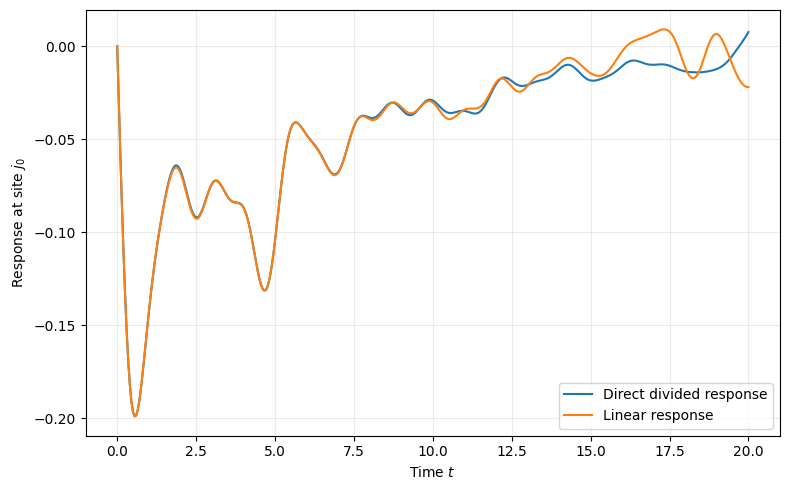

In [ ]:

probe_site = L // 2

plt.figure(figsize=(8, 5))
plt.plot(
    operator_sample_times,
    np.real(chi_direct_sampled[:, probe_site]),
    #"o-",
    label="Direct divided response",
)
plt.plot(
    operator_sample_times,
    np.real(chi_time[:, probe_site]),
    #"s--",
    label="Linear response",
)

plt.xlabel(r"Time $t$")
plt.ylabel(r"Response at site $j_0$")
#plt.title(
#    rf"Direct versus linear response at site $j={probe_site}$"
#)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()



### Plot 2 — Linear-response light cone and direct-versus-LR error


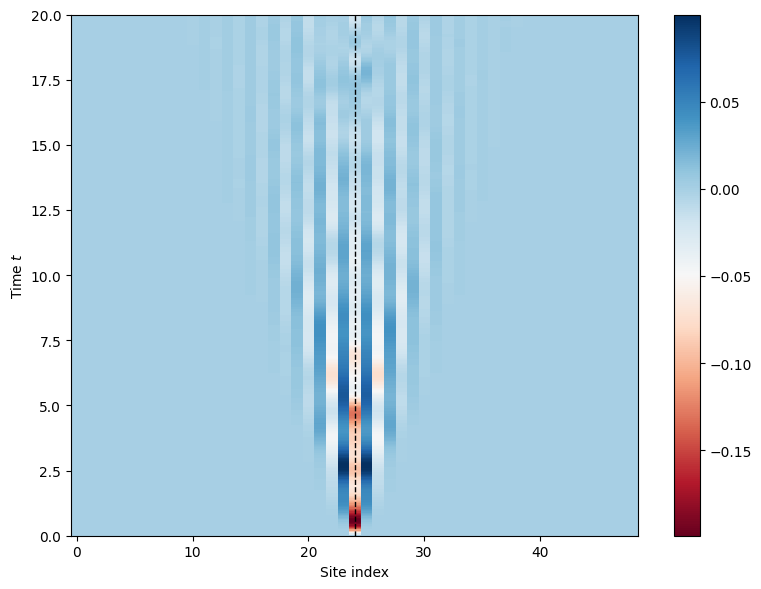

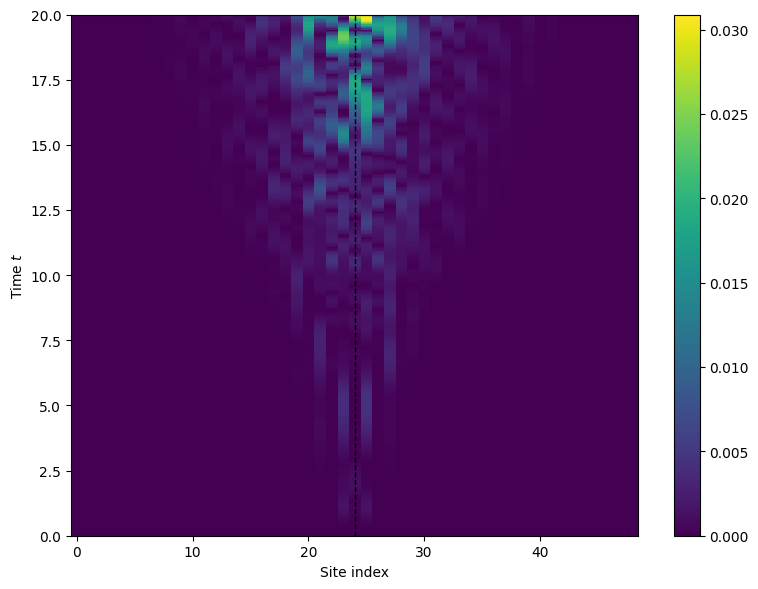

In [ ]:

plt.figure(figsize=(8, 6))
plt.imshow(
    np.real(chi_time),
    aspect="auto",
    origin="lower",
    cmap="RdBu",
    interpolation="none",
    extent=[
        -0.5,
        L - 0.5,
        operator_sample_times[0],
        operator_sample_times[-1],
    ],
)
plt.colorbar()
#plt.colorbar(label=r"$\chi_j(t)$")
plt.axvline(L // 2, color="black", linestyle="--", linewidth=1)
plt.xlabel("Site index")
plt.ylabel(r"Time $t$")
#plt.title("Linear-response light cone")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(
    comparison_error_time,
    aspect="auto",
    origin="lower",
    interpolation="none",
    extent=[
        -0.5,
        L - 0.5,
        operator_sample_times[0],
        operator_sample_times[-1],
    ],
)

plt.colorbar()
#plt.colorbar(label=r"$|R_j^{\rm dir}(t)-\chi_j(t)|$")
plt.axvline(L // 2, color="black", linestyle="--", linewidth=1)
plt.xlabel("Site index")
plt.ylabel(r"Time $t$")
#plt.title("Absolute direct-versus-linear-response error")
plt.tight_layout()
plt.show()



### Plot 3 — Growth of tensor-network complexity

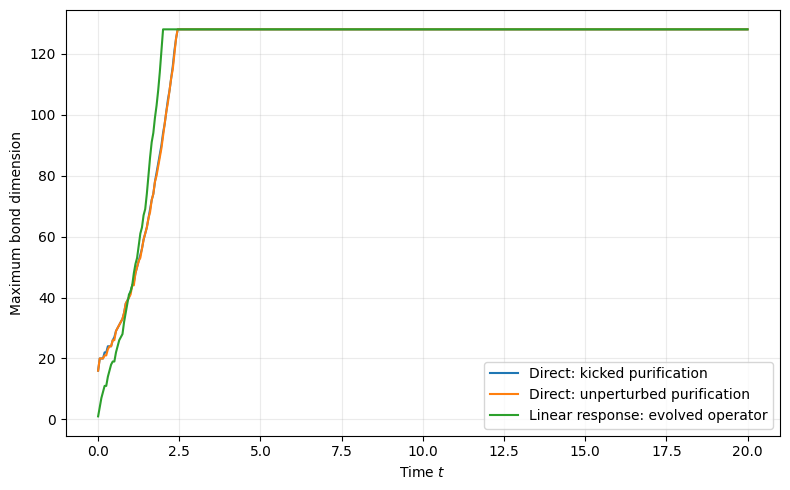

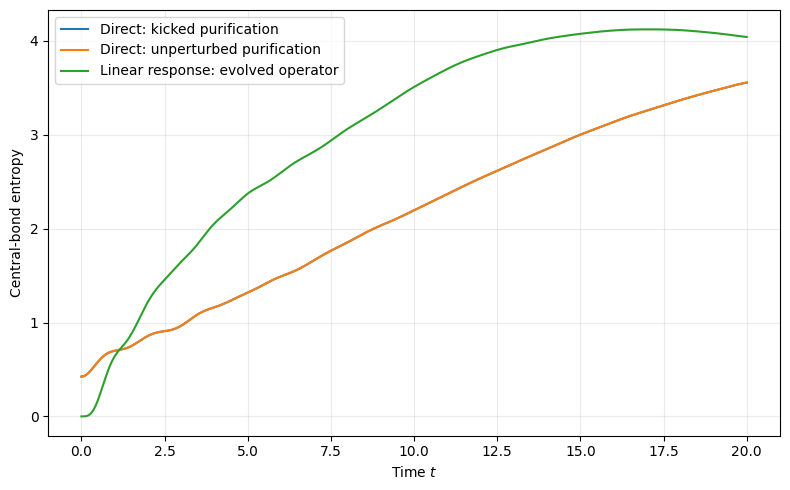

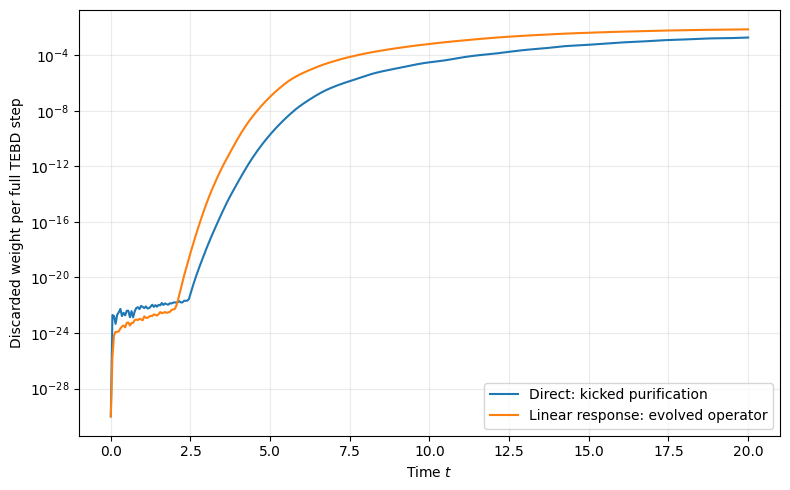

In [ ]:

plt.figure(figsize=(8, 5))
plt.plot(
    kicked_diagnostics["times"],
    kicked_diagnostics["max_bond_dimension"],
    label="Direct: kicked purification",
)
plt.plot(
    unperturbed_diagnostics["times"],
    unperturbed_diagnostics["max_bond_dimension"],
    label="Direct: unperturbed purification",
)
plt.plot(
    operator_diagnostics["times"],
    operator_diagnostics["max_bond_dimension"],
    label="Linear response: evolved operator",
)
plt.xlabel(r"Time $t$")
plt.ylabel("Maximum bond dimension")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    kicked_diagnostics["times"],
    kicked_diagnostics["half_chain_entropy"],
    label="Direct: kicked purification",
)
plt.plot(
    unperturbed_diagnostics["times"],
    unperturbed_diagnostics["half_chain_entropy"],
    label="Direct: unperturbed purification",
)
plt.plot(
    operator_diagnostics["times"],
    operator_diagnostics["half_chain_entropy"],
    label="Linear response: evolved operator",
)
plt.xlabel(r"Time $t$")
plt.ylabel("Central-bond entropy")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.semilogy(
    kicked_diagnostics["times"],
    np.maximum(
        kicked_diagnostics["step_discarded_weight"],
        1e-30,
    ),
    label="Direct: kicked purification",
)
plt.semilogy(
    operator_diagnostics["times"],
    np.maximum(
        operator_diagnostics["step_discarded_weight"],
        1e-30,
    ),
    label="Linear response: evolved operator",
)
plt.xlabel(r"Time $t$")
plt.ylabel("Discarded weight per full TEBD step")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()



### Optional Plot 4 — Thermal-state complexity versus inverse temperature

Only the final thermal MPS is required for this plot; the existing
thermal-preparation task is reused without changing its place in the
notebook.


0it [00:00, ?it/s]
100%|██████████| 1600/1600 [1:03:36<00:00,  2.39s/it]


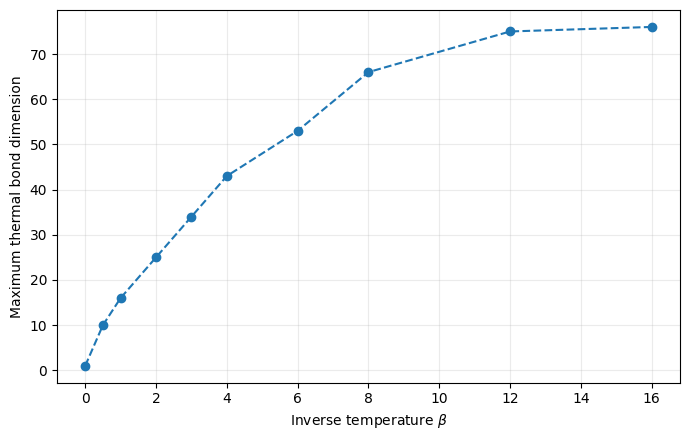

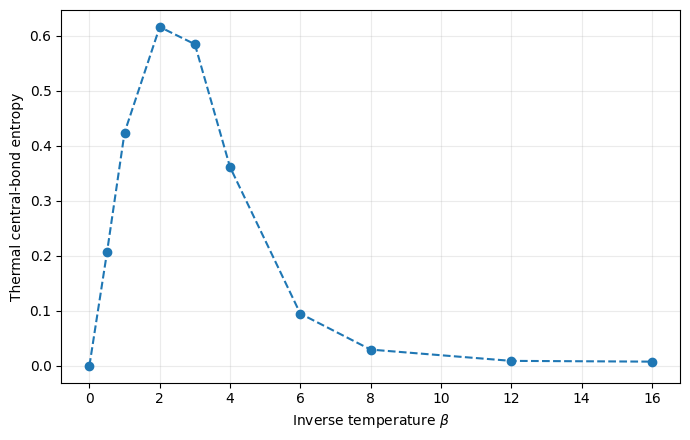

In [ ]:

RUN_BETA_SCAN = True

if RUN_BETA_SCAN:
    beta_values = [0.0, 0.5, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0]
    beta_max_bond = []
    beta_entropy = []

    for current_beta in beta_values:
        current_thermal_mps, _ = (
            prepare_finite_temperature_purification(
                J,
                h,
                g,
                L,
                current_beta,
                dt,
                chi_max,
                eps,
                sz_purified,
            )
        )

        current_complexity = mps_complexity(
            current_thermal_mps
        )

        beta_max_bond.append(
            current_complexity["max_bond_dimension"]
        )
        beta_entropy.append(
            current_complexity["half_chain_entropy"]
        )

    plt.figure(figsize=(7, 4.5))
    plt.plot(beta_values, beta_max_bond, "o--")
    plt.xlabel(r"Inverse temperature $\beta$")
    plt.ylabel("Maximum thermal bond dimension")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 4.5))
    plt.plot(beta_values, beta_entropy, "o--")
    plt.xlabel(r"Inverse temperature $\beta$")
    plt.ylabel("Thermal central-bond entropy")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()



### Optional Plot 5 — Kick-strength scan

This cell is deliberately disabled by default because it repeats the
direct evolution.  For smaller $\lambda$, the divided direct response
should approach the same linear-response curve.


In [ ]:
RUN_LAMBDA_SCAN = False

if RUN_LAMBDA_SCAN:

    # Only calculate the lambda values that have NOT already been run
    lambda_values = [0.1, 0.5]

    # Reuse the already-computed lambda = 0.01 result
    lambda_responses = {
        0.01: (
            np.real(np.asarray(sz_time_history))
            - np.real(np.asarray(sz_unpertubed_time_history))
        ) / 0.01
    }

    # The unperturbed reference is independent of lambda and is reused.
    unperturbed_history_array = np.real(
        np.asarray(sz_unpertubed_time_history)
    )

    for current_lambda in lambda_values:

        current_kick = apply_local_kick(
            mps=psi_beta,
            operator=local_kick_operator(
                current_lambda,
                sz_purified,
            ),
            site=L // 2,
        )

        _, current_history = tebd_run(
            initial_mps=current_kick,
            list_of_bond_hams=list_of_ham_bonds(J, h, g, L),
            dt=real_dt,
            n_steps=real_n_steps,
            chi_max=chi_max,
            eps=eps,
            O=sz_purified,
        )

        lambda_responses[current_lambda] = (
            np.real(np.asarray(current_history))
            - unperturbed_history_array
        ) / current_lambda

    plt.figure(figsize=(8, 5))

    for current_lambda, response in lambda_responses.items():
        plt.plot(
            operator_sample_times,
            response[operator_sample_steps, probe_site],
            label=rf"$\lambda={current_lambda}$",
        )

    plt.plot(
        operator_sample_times,
        np.real(chi_time[:, probe_site]),
        "k--",
        linewidth=2,
        label="Linear response",
    )

    plt.xlabel(r"Time $t$")
    plt.ylabel("Divided response")
    # plt.title(rf"Kick-strength scan at site $j={probe_site}$")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()